# Εργαστήριο 1: Wide ResNets στο CIFAR-10

**Πρόβλημα.** Ταξινόμηση εικόνων του CIFAR-10 (60.000 έγχρωμες εικόνες 32×32 σε 10 κλάσεις: αεροπλάνο, αυτοκίνητο, πουλί, γάτα, ελάφι, σκύλος, βάτραχος, άλογο, πλοίο, φορτηγό) με *wide residual networks* (WRN, Zagoruyko και Komodakis, 2016). Ένα WRN-n-k έχει n επίπεδα συνέλιξης και k φορές περισσότερα κανάλια από το αντίστοιχο «λεπτό» ResNet. Το paper δείχνει ότι ένα ρηχότερο αλλά πλατύτερο δίκτυο μπορεί να είναι και ακριβέστερο και ταχύτερο από ένα πολύ βαθύ και λεπτό.

**Ζητούμενα.**
1. **Πλάτος και βάθος:** εκπαίδευση των τριών καλύτερων WRN του paper με μέτρια επαύξηση δεδομένων (Πίνακας 5): WRN-40-4, WRN-16-8 και WRN-28-10.
2. **Dropout:** τα ίδια μοντέλα με dropout 0,3 ανάμεσα στις δύο συνελίξεις κάθε block, όπως στο paper.
3. **MixUp και ανθεκτικότητα:** το καλύτερο μοντέλο εκπαιδεύεται για 5 ακόμη εποχές, μία φορά χωρίς και μία με MixUp, και αξιολογείται στο CIFAR-10-C. Το CIFAR-10-C περιέχει τις εικόνες του test set με 15 είδη αλλοιώσεων (θόρυβος, θόλωμα, καιρικά φαινόμενα, ψηφιακές αλλοιώσεις) σε 5 βαθμούς έντασης.
4. **Bonus:** σύγκριση της βεβαιότητας των προβλέψεων (μέγιστη πιθανότητα του softmax) χωρίς και με MixUp.

**Πρωτόκολλο.**
- **Δεδομένα:** από τις 50.000 εικόνες εκπαίδευσης κρατάμε 20.000 για εκπαίδευση (2.000 ανά κλάση) και 5.000 για validation (500 ανά κλάση). Τα δύο σύνολα είναι ξένα μεταξύ τους και επιλέγονται με σταθερό seed. Οι 10.000 εικόνες του test set χρησιμοποιούνται μόνο για την τελική αξιολόγηση.
- **Εκπαίδευση:** 15 εποχές με batch 128 και SGD με Nesterov momentum 0,9. Το learning rate ξεκινά από 0,1 και μειώνεται έως το 0 με καμπύλη συνημιτόνου. Weight decay 5·10⁻⁴. Είναι οι ρυθμίσεις του paper, με λιγότερες εποχές.
- **Επαύξηση και κανονικοποίηση:** τυχαίο κόψιμο 32×32 από την εικόνα με περιθώριο 4 pixel (με ανάκλαση) και τυχαία οριζόντια αναστροφή. Κανονικοποίηση με τον μέσο όρο και την τυπική απόκλιση κάθε καναλιού.
- **Επαναλήψεις:** κάθε πείραμα τρέχει με 3 seeds (0, 1, 2) και αναφέρουμε μέσο όρο και τυπική απόκλιση.
- **Επιλογή μοντέλου:** γίνεται μόνο με το validation accuracy.
- **Ζητούμενο 3:** η εκπαίδευση συνεχίζεται 5 εποχές από το checkpoint των 15 εποχών, με learning rate από 0,01 έως 0 και την ίδια επαύξηση. Η μόνη διαφορά των δύο εκδοχών είναι το MixUp με α = 0,2.
- **CIFAR-10-C:** 15 αλλοιώσεις × 5 εντάσεις, στις ίδιες 2.000 εικόνες του test set για όλα τα μοντέλα.

Ο κώδικας βρίσκεται στο `wrn_lab.py`· το notebook τον γράφει στον δίσκο, τον εκτελεί και αναλύει τα αποτελέσματα. Η εκπαίδευση έγινε σε GPU του Kaggle (2× NVIDIA T4) με mixed precision. Κάθε GPU εκτελεί ξεχωριστή διεργασία, η οποία παίρνει το επόμενο πείραμα από μια κοινή λίστα.

In [1]:
import os, sys, json, time, subprocess, shutil
from pathlib import Path

SMOKE = os.environ.get("LAB_SMOKE") == "1"          # tiny CPU test of the code only; never used for the results
ON_KAGGLE = Path("/kaggle/working").exists()
WORK = Path("/kaggle/working") if ON_KAGGLE else Path.cwd()
OUT = WORK / ("outputs_smoke" if SMOKE else "outputs") / "lab1"      # results, tables, figures
DATA = Path("/tmp/lab1_data") if ON_KAGGLE else WORK / "_data_lab1"  # datasets (not kept as output)
CKPT = Path("/tmp/lab1_ckpt") if ON_KAGGLE else WORK / "_ckpt_lab1"  # model weights (not kept as output)
START = time.time()
DEADLINE = START + 10.5 * 3600   # Kaggle ends a session after 12 hours: no new run starts after 10.5 hours

Ο κώδικας των πειραμάτων (μοντέλο, δεδομένα, εκπαίδευση, αξιολόγηση και οι διεργασίες ανά GPU):

In [2]:
%%writefile wrn_lab.py
"""Wide ResNets on CIFAR-10: depth/width and dropout study, MixUp fine-tuning, CIFAR-10-C robustness.

The notebook `lab1_wide_resnet_cifar10.ipynb` drives this module:
    prepare(...)                      downloads CIFAR-10 and CIFAR-10-C and builds the fixed splits
    python wrn_lab.py worker ...      one process per GPU; takes jobs from the shared list until none is left

Every job writes one JSON file to <out>/results/, so a run can stop and resume without losing finished work.
"""
import argparse
import hashlib
import json
import math
import os
import shutil
import sys
import tarfile
import time
import urllib.request
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

# ----------------------------------------------------------------------------- settings

CORRUPTIONS = {   # the 15 corruptions of the CIFAR-10-C benchmark, in its four groups
    "noise": ["gaussian_noise", "shot_noise", "impulse_noise"],
    "blur": ["defocus_blur", "glass_blur", "motion_blur", "zoom_blur"],
    "weather": ["snow", "frost", "fog", "brightness"],
    "digital": ["contrast", "elastic_transform", "pixelate", "jpeg_compression"],
}
CIFAR10C_URL = "https://zenodo.org/records/2535967/files/CIFAR-10-C.tar"
CIFAR10C_MD5 = "56bf5dcef84df0e2308c6dcbcbbd8499"
CIFAR10C_BYTES = 2918471680
CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]


def make_plan(smoke=False):
    """All experiment settings in one place. `smoke` is a tiny version used only to test the code on a CPU."""
    plan = dict(
        configs=[[40, 4], [16, 8], [28, 10]],   # depth, widening factor: the three best WRNs of Table 5 in the paper
        dropouts=[0.0, 0.3],                    # 0.3 is the paper's dropout rate for CIFAR
        seeds=[0, 1, 2],
        split_seed=1234,
        n_train_per_class=2000,                 # 20,000 training images (40% of the training set)
        n_val_per_class=500,                    # 5,000 validation images, also from the training set
        epochs=15, batch=128, lr=0.1, momentum=0.9, weight_decay=5e-4,
        ft_epochs=5, ft_lr=0.01, mixup_alpha=0.2,
        c_per_severity=2000,                    # CIFAR-10-C images per corruption and severity (same images everywhere)
        corruptions=CORRUPTIONS,
        eval_batch=1000,
        smoke=False,
    )
    if smoke:
        plan.update(configs=[[10, 1], [10, 2]], seeds=[0, 1], n_train_per_class=24, n_val_per_class=8,
                    epochs=2, batch=32, ft_epochs=1, c_per_severity=16, eval_batch=64, smoke=True,
                    corruptions={g: v[:2] for g, v in CORRUPTIONS.items()})
    return plan


def corruption_names(plan):
    return [c for group in plan["corruptions"].values() for c in group]


def sweep_jobs(plan):
    """Parts 1 and 2: every architecture with and without dropout, for each seed (largest models first)."""
    jobs = []
    for seed in plan["seeds"]:
        for depth, k in sorted(plan["configs"], key=lambda c: -c[0] * c[1] ** 2):
            for p in plan["dropouts"]:
                jobs.append(dict(kind="sweep", depth=depth, k=k, dropout=p, seed=seed,
                                 name=f"wrn{depth}-{k}_drop{p:.1f}_seed{seed}"))
    return jobs


def mixup_jobs(plan, best):
    """Part 3 and the bonus: the chosen model before and after 5 more epochs, without and with MixUp."""
    jobs = []
    for seed in plan["seeds"]:
        for kind in ("base", "nomixup", "mixup"):
            jobs.append(dict(kind=kind, depth=best["depth"], k=best["k"], dropout=best["dropout"], seed=seed,
                             name=f"{kind}_seed{seed}"))
    return jobs


# ----------------------------------------------------------------------------- model

class Block(nn.Module):
    """Pre-activation basic block of a wide ResNet: BN-ReLU-conv3x3, dropout, BN-ReLU-conv3x3."""

    def __init__(self, c_in, c_out, stride, dropout):
        super().__init__()
        self.bn1 = nn.BatchNorm2d(c_in)
        self.conv1 = nn.Conv2d(c_in, c_out, 3, stride, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, 1, 1, bias=False)
        self.dropout = dropout
        self.shortcut = None if (c_in == c_out and stride == 1) else nn.Conv2d(c_in, c_out, 1, stride, 0, bias=False)

    def forward(self, x):
        o = F.relu(self.bn1(x))
        y = self.conv1(o)
        y = F.relu(self.bn2(y))
        if self.dropout > 0:
            y = F.dropout(y, p=self.dropout, training=self.training)
        y = self.conv2(y)
        return y + (x if self.shortcut is None else self.shortcut(o))


class WideResNet(nn.Module):
    """WRN-depth-k (Zagoruyko and Komodakis, 2016): 3 groups of (depth-4)/6 blocks, widths 16k, 32k, 64k."""

    def __init__(self, depth, k, dropout=0.0, num_classes=10):
        super().__init__()
        assert (depth - 4) % 6 == 0, "depth must be 6n+4"
        n = (depth - 4) // 6
        widths = [16, 16 * k, 32 * k, 64 * k]
        self.conv = nn.Conv2d(3, widths[0], 3, 1, 1, bias=False)
        blocks = []
        for g, stride in enumerate((1, 2, 2)):
            for b in range(n):
                blocks.append(Block(widths[g] if b == 0 else widths[g + 1], widths[g + 1],
                                    stride if b == 0 else 1, dropout))
        self.blocks = nn.Sequential(*blocks)
        self.bn = nn.BatchNorm2d(widths[3])
        self.fc = nn.Linear(widths[3], num_classes)
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                nn.init.zeros_(m.bias)

    def forward(self, x):
        x = F.relu(self.bn(self.blocks(self.conv(x))))
        return self.fc(F.adaptive_avg_pool2d(x, 1).flatten(1))


def count_params(model):
    return sum(p.numel() for p in model.parameters())


# ----------------------------------------------------------------------------- data

def _md5_download(url, dest, md5, size=None, tries=3):
    for attempt in range(1, tries + 1):
        h, done, t0 = hashlib.md5(), 0, time.time()
        try:
            with urllib.request.urlopen(url, timeout=120) as r, open(dest, "wb") as f:
                while True:
                    chunk = r.read(1 << 22)
                    if not chunk:
                        break
                    f.write(chunk)
                    h.update(chunk)
                    done += len(chunk)
                    if size and done % (1 << 29) < (1 << 22):
                        print(f"  {done / 1e9:.1f} of {size / 1e9:.1f} GB ({time.time() - t0:.0f} s)", flush=True)
            if h.hexdigest() == md5:
                return
            print(f"  checksum mismatch on attempt {attempt}", flush=True)
        except OSError as e:
            print(f"  download error on attempt {attempt}: {e}", flush=True)
    raise RuntimeError(f"could not download {url} with the expected checksum")


def _fake_images(rng, labels):
    """Smoke test only: random images whose average colour depends on the class, so a model can learn a little."""
    base = np.linspace(40, 215, 10)
    x = rng.normal(base[labels][:, None, None, None], 35, size=(len(labels), 32, 32, 3))
    return x.clip(0, 255).astype(np.uint8)


def prepare(plan, data_dir):
    """Build <data>/cifar10_split.npz and <data>/cifar10c_subset.npz once (skipped when they already exist)."""
    data_dir = Path(data_dir)
    data_dir.mkdir(parents=True, exist_ok=True)
    split_file, c_file = data_dir / "cifar10_split.npz", data_dir / "cifar10c_subset.npz"
    rng = np.random.default_rng(plan["split_seed"])
    names = corruption_names(plan)

    if not split_file.exists():
        if plan["smoke"]:
            y_all = np.repeat(np.arange(10), 60)
            x_all = _fake_images(rng, y_all)
            y_test = np.repeat(np.arange(10), 20)
            x_test = _fake_images(rng, y_test)
        else:
            from torchvision.datasets import CIFAR10
            tr = CIFAR10(str(data_dir / "cifar10"), train=True, download=True)
            te = CIFAR10(str(data_dir / "cifar10"), train=False, download=True)
            x_all, y_all = tr.data, np.array(tr.targets)
            x_test, y_test = te.data, np.array(te.targets)
        tr_idx, va_idx = [], []
        for c in range(10):   # class-balanced, disjoint training and validation sets from the official training set
            idx = rng.permutation(np.flatnonzero(y_all == c))
            va_idx.append(idx[:plan["n_val_per_class"]])
            tr_idx.append(idx[plan["n_val_per_class"]:plan["n_val_per_class"] + plan["n_train_per_class"]])
        tr_idx, va_idx = np.sort(np.concatenate(tr_idx)), np.sort(np.concatenate(va_idx))
        x_train = x_all[tr_idx]
        mean = x_train.reshape(-1, 3).mean(0) / 255
        std = x_train.reshape(-1, 3).std(0) / 255
        np.savez(split_file, x_train=x_train, y_train=y_all[tr_idx], x_val=x_all[va_idx], y_val=y_all[va_idx],
                 x_test=x_test, y_test=y_test, mean=mean, std=std, train_index=tr_idx, val_index=va_idx)
        shutil.rmtree(data_dir / "cifar10", ignore_errors=True)

    if not c_file.exists():
        n_test = 10000 if not plan["smoke"] else 200
        pick = np.sort(rng.choice(n_test, plan["c_per_severity"], replace=False))
        x_c = np.empty((len(names), 5, len(pick), 32, 32, 3), np.uint8)
        if plan["smoke"]:
            y_test = np.load(split_file)["y_test"]
            y_c = y_test[pick]
            for i in range(len(names)):
                for s in range(5):
                    x_c[i, s] = _fake_images(np.random.default_rng(100 * i + s), y_c)
        else:
            tar_path, raw = data_dir / "CIFAR-10-C.tar", data_dir / "CIFAR-10-C_raw"
            print(f"Downloading CIFAR-10-C ({CIFAR10C_BYTES / 1e9:.1f} GB) from Zenodo ...", flush=True)
            _md5_download(CIFAR10C_URL, tar_path, CIFAR10C_MD5, CIFAR10C_BYTES)
            wanted = {f"{n}.npy" for n in names + ["labels"]}
            raw.mkdir(exist_ok=True)
            with tarfile.open(tar_path) as tar:
                for m in tar.getmembers():
                    base = m.name.rsplit("/", 1)[-1]
                    if m.isfile() and base in wanted:
                        with tar.extractfile(m) as src, open(raw / base, "wb") as dst:
                            shutil.copyfileobj(src, dst, 1 << 22)
            missing = wanted - {p.name for p in raw.iterdir()}
            assert not missing, f"not found in the CIFAR-10-C archive: {sorted(missing)}"
            tar_path.unlink()
            labels = np.load(raw / "labels.npy")
            y_c = labels[pick]
            for s in range(5):   # the labels repeat for each of the 5 severities
                assert np.array_equal(labels[s * 10000 + pick], y_c)
            assert np.array_equal(y_c, np.load(split_file)["y_test"][pick])
            for i, n in enumerate(names):
                arr = np.load(raw / f"{n}.npy", mmap_mode="r")
                for s in range(5):
                    x_c[i, s] = arr[s * 10000 + pick]
                del arr   # release the memory map before the file is deleted
            shutil.rmtree(raw)
        np.savez(c_file, x=x_c, y=y_c, names=np.array(names), test_index=pick)

    d = np.load(split_file)
    return {"train": len(d["y_train"]), "val": len(d["y_val"]), "test": len(d["y_test"]),
            "cifar10c": f"{len(names)} corruptions x 5 severities x {plan['c_per_severity']} images"}


class Data:
    """Keeps the image arrays on the device as uint8 and turns them into normalized float batches on demand."""

    def __init__(self, data_dir, device):
        d = np.load(Path(data_dir) / "cifar10_split.npz")
        self.device = device
        to = lambda a: torch.from_numpy(np.ascontiguousarray(a)).to(device)
        self.x = {s: to(d[f"x_{s}"]) for s in ("train", "val", "test")}
        self.y = {s: to(d[f"y_{s}"]).long() for s in ("train", "val", "test")}
        self.mean = torch.tensor(d["mean"], dtype=torch.float32, device=device).view(1, 3, 1, 1)
        self.std = torch.tensor(d["std"], dtype=torch.float32, device=device).view(1, 3, 1, 1)
        self._c = None
        self.data_dir = Path(data_dir)

    def to_float(self, xb):
        x = xb.permute(0, 3, 1, 2).float().div_(255)
        return ((x - self.mean) / self.std).contiguous(memory_format=torch.channels_last)

    @property
    def corrupted(self):
        if self._c is None:
            c = np.load(self.data_dir / "cifar10c_subset.npz")
            self._c = dict(x=c["x"], y=torch.from_numpy(c["y"]).long().to(self.device), names=list(c["names"]))
        return self._c


def augment(x, g):
    """Random 32x32 crop of the image padded by 4 pixels with reflections, then a random horizontal flip."""
    b, dev = x.shape[0], x.device
    xp = F.pad(x, (4, 4, 4, 4), mode="reflect")
    i = torch.randint(0, 9, (b,), device=dev, generator=g)
    j = torch.randint(0, 9, (b,), device=dev, generator=g)
    ar = torch.arange(32, device=dev)
    rows = (i[:, None] + ar)[:, :, None]
    cols = (j[:, None] + ar)[:, None, :]
    out = xp[torch.arange(b, device=dev)[:, None, None], :, rows, cols].permute(0, 3, 1, 2)
    flip = torch.rand(b, device=dev, generator=g) < 0.5
    out = torch.where(flip[:, None, None, None], out.flip(3), out)
    return out.contiguous(memory_format=torch.channels_last)


# ----------------------------------------------------------------------------- training and evaluation

def _autocast(device):
    return torch.autocast(device_type="cuda", dtype=torch.float16, enabled=str(device).startswith("cuda"))


def _scaler(device):
    on = str(device).startswith("cuda")
    try:
        return torch.amp.GradScaler("cuda", enabled=on)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=on)


@torch.no_grad()
def predict(model, data, xs, ys, batch):
    """Softmax probabilities (float32, on the CPU) and the mean cross-entropy for uint8 images xs with labels ys."""
    model.eval()
    probs, loss_sum = [], 0.0
    for s in range(0, len(xs), batch):
        xb = xs[s:s + batch]
        if not torch.is_tensor(xb):
            xb = torch.from_numpy(np.ascontiguousarray(xb)).to(data.device)
        with _autocast(data.device):
            logits = model(data.to_float(xb)).float()
        loss_sum += F.cross_entropy(logits, ys[s:s + batch], reduction="sum").item()
        probs.append(F.softmax(logits, 1).cpu())
    return torch.cat(probs), loss_sum / len(xs)


def train(model, data, plan, seed, epochs, lr0, mixup_alpha=0.0, log=print, tag=""):
    """SGD with Nesterov momentum and a cosine learning rate from lr0 to 0; validation after every epoch."""
    dev = data.device
    torch.manual_seed(seed)
    g_shuffle = torch.Generator().manual_seed(seed)
    g_aug = torch.Generator(device=dev).manual_seed(seed + 10_000)
    np_rng = np.random.default_rng(seed + 20_000)
    opt = torch.optim.SGD(model.parameters(), lr=lr0, momentum=plan["momentum"], nesterov=True,
                          weight_decay=plan["weight_decay"])
    scaler = _scaler(dev)
    n, bs = len(data.y["train"]), plan["batch"]
    steps = math.ceil(n / bs)
    total, step = epochs * steps, 0
    hist = {k: [] for k in ("train_loss", "train_acc", "val_loss", "val_acc", "seconds")}
    for epoch in range(epochs):
        model.train()
        t0 = time.time()
        perm = torch.randperm(n, generator=g_shuffle).to(dev)
        loss_sum = correct = 0.0
        for s in range(0, n, bs):
            lr = 0.5 * lr0 * (1 + math.cos(math.pi * step / total))
            for group in opt.param_groups:
                group["lr"] = lr
            idx = perm[s:s + bs]
            x = augment(data.to_float(data.x["train"][idx]), g_aug)
            y = data.y["train"][idx]
            with _autocast(dev):
                if mixup_alpha > 0:   # MixUp (Zhang et al., 2018): blend each image with another one of the batch
                    lam = float(np_rng.beta(mixup_alpha, mixup_alpha))
                    other = torch.randperm(len(y), device=dev, generator=g_aug)
                    out = model(lam * x + (1 - lam) * x[other])
                    loss = lam * F.cross_entropy(out, y) + (1 - lam) * F.cross_entropy(out, y[other])
                else:
                    out = model(x)
                    loss = F.cross_entropy(out, y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            pred = out.argmax(1)
            if mixup_alpha > 0:
                hits = lam * (pred == y).sum() + (1 - lam) * (pred == y[other]).sum()
            else:
                hits = (pred == y).sum()
            loss_sum += loss.item() * len(y)
            correct += float(hits)
            step += 1
        probs, val_loss = predict(model, data, data.x["val"], data.y["val"], plan["eval_batch"])
        val_acc = (probs.argmax(1) == data.y["val"].cpu()).float().mean().item()
        hist["train_loss"].append(loss_sum / n)
        hist["train_acc"].append(correct / n)
        hist["val_loss"].append(val_loss)
        hist["val_acc"].append(val_acc)
        hist["seconds"].append(time.time() - t0)
        log(f"{tag} epoch {epoch + 1}/{epochs}: train loss {loss_sum / n:.3f}, train acc {correct / n:.3f}, "
            f"val acc {val_acc:.4f} ({time.time() - t0:.0f} s, {n / (time.time() - t0):.0f} img/s)")
    return hist


def confidence_stats(probs, labels, n_bins=15, n_hist=20):
    """Confidence = largest softmax probability. Histograms for right and wrong answers, and calibration (ECE)."""
    conf, pred = probs.max(1)
    right = (pred == labels).numpy()
    conf = conf.numpy().astype(np.float64)
    edges = np.linspace(0, 1, n_bins + 1)
    which = np.clip(np.digitize(conf, edges[1:-1]), 0, n_bins - 1)
    bin_acc, bin_conf, bin_count = [], [], []
    ece = 0.0
    for b in range(n_bins):
        m = which == b
        cnt = int(m.sum())
        bin_count.append(cnt)
        bin_acc.append(float(right[m].mean()) if cnt else None)
        bin_conf.append(float(conf[m].mean()) if cnt else None)
        if cnt:
            ece += cnt / len(conf) * abs(right[m].mean() - conf[m].mean())
    h_edges = np.linspace(0, 1, n_hist + 1)
    return dict(acc=float(right.mean()), mean_conf=float(conf.mean()),
                mean_conf_right=float(conf[right].mean()) if right.any() else None,
                mean_conf_wrong=float(conf[~right].mean()) if (~right).any() else None,
                ece=float(ece), bin_acc=bin_acc, bin_conf=bin_conf, bin_count=bin_count,
                hist_right=np.histogram(conf[right], h_edges)[0].tolist(),
                hist_wrong=np.histogram(conf[~right], h_edges)[0].tolist(), n=int(len(conf)))


def evaluate_robustness(model, data, plan):
    """Clean test set and every CIFAR-10-C corruption and severity."""
    probs, test_loss = predict(model, data, data.x["test"], data.y["test"], plan["eval_batch"])
    clean = confidence_stats(probs, data.y["test"].cpu())
    clean["loss"] = test_loss
    c = data.corrupted
    acc = np.zeros((len(c["names"]), 5))
    all_probs = []
    for i in range(len(c["names"])):
        for s in range(5):
            p, _ = predict(model, data, c["x"][i, s], c["y"], plan["eval_batch"])
            acc[i, s] = (p.argmax(1) == c["y"].cpu()).float().mean().item()
            all_probs.append(p)
    corrupted = confidence_stats(torch.cat(all_probs), c["y"].cpu().repeat(len(c["names"]) * 5))
    return dict(clean=clean, cifar10c=dict(names=c["names"], acc=acc.tolist(), mean_acc=float(acc.mean()),
                                           confidence=corrupted))


# ----------------------------------------------------------------------------- jobs and workers

def run_job(job, plan, data, ckpt_dir, log):
    t0 = time.time()
    model = None
    torch.manual_seed(job["seed"])
    model = WideResNet(job["depth"], job["k"], job["dropout"]).to(data.device).to(memory_format=torch.channels_last)
    res = dict(job=job, params=count_params(model))
    base_ckpt = Path(ckpt_dir) / f"wrn{job['depth']}-{job['k']}_drop{job['dropout']:.1f}_seed{job['seed']}.pt"
    if job["kind"] == "sweep":
        res["history"] = train(model, data, plan, job["seed"], plan["epochs"], plan["lr"], log=log, tag=job["name"])
        probs, test_loss = predict(model, data, data.x["test"], data.y["test"], plan["eval_batch"])
        res["val_acc"] = res["history"]["val_acc"][-1]
        res["test_acc"] = (probs.argmax(1) == data.y["test"].cpu()).float().mean().item()
        res["test_loss"] = test_loss
        torch.save(model.state_dict(), base_ckpt)
    else:
        model.load_state_dict(torch.load(base_ckpt, map_location=data.device, weights_only=True))
        if job["kind"] != "base":
            alpha = plan["mixup_alpha"] if job["kind"] == "mixup" else 0.0
            res["history"] = train(model, data, plan, job["seed"] + 100, plan["ft_epochs"], plan["ft_lr"],
                                   mixup_alpha=alpha, log=log, tag=job["name"])
        res.update(evaluate_robustness(model, data, plan))
    res["seconds"] = time.time() - t0
    res["device"] = torch.cuda.get_device_name(data.device) if str(data.device).startswith("cuda") else "cpu"
    return res


def worker(phase, device, data_dir, out_dir, ckpt_dir, deadline):
    out_dir, ckpt_dir = Path(out_dir), Path(ckpt_dir)
    plan = json.loads((out_dir / "plan.json").read_text())
    if phase == "sweep":
        jobs = sweep_jobs(plan)
    else:
        jobs = mixup_jobs(plan, json.loads((out_dir / "best.json").read_text()))
    for d in ("results", "locks", "logs"):
        (out_dir / d).mkdir(parents=True, exist_ok=True)
    ckpt_dir.mkdir(parents=True, exist_ok=True)
    tag = device.replace(":", "")
    logf = open(out_dir / "logs" / f"{phase}_{tag}.log", "a", encoding="utf8")

    def log(msg):
        line = f"[{time.strftime('%H:%M:%S')} {tag}] {msg}"
        print(line, flush=True)
        logf.write(line + "\n")
        logf.flush()

    if device.startswith("cuda"):
        torch.cuda.set_device(device)
        torch.backends.cudnn.benchmark = True
    data = Data(data_dir, device)
    for job in jobs:
        result_file = out_dir / "results" / f"{job['name']}.json"
        if result_file.exists():
            continue
        try:
            fd = os.open(out_dir / "locks" / f"{job['name']}.lock", os.O_CREAT | os.O_EXCL | os.O_WRONLY)
            os.close(fd)
        except FileExistsError:
            continue
        if time.time() > deadline:
            log(f"time limit reached, not starting {job['name']}")
            os.remove(out_dir / "locks" / f"{job['name']}.lock")
            break
        log(f"start {job['name']}")
        res = run_job(job, plan, data, ckpt_dir, log)
        tmp = result_file.with_suffix(".tmp")
        tmp.write_text(json.dumps(res))
        tmp.replace(result_file)
        log(f"done {job['name']} in {res['seconds'] / 60:.1f} min")
    logf.close()


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    sub = ap.add_subparsers(dest="cmd", required=True)
    w = sub.add_parser("worker")
    w.add_argument("--phase", choices=["sweep", "mixup"], required=True)
    w.add_argument("--device", required=True)
    w.add_argument("--data", required=True)
    w.add_argument("--out", required=True)
    w.add_argument("--ckpt", required=True)
    w.add_argument("--deadline", type=float, default=float("inf"))
    a = ap.parse_args()
    worker(a.phase, a.device, a.data, a.out, a.ckpt, a.deadline)
    sys.exit(0)

Writing wrn_lab.py


In [3]:
import numpy as np
import torch
import wrn_lab

plan = wrn_lab.make_plan(SMOKE)
OUT.mkdir(parents=True, exist_ok=True)
(OUT / "plan.json").write_text(json.dumps(plan, indent=1))
n_gpu = torch.cuda.device_count()
if n_gpu == 0 and not SMOKE:
    raise RuntimeError("No GPU found. In the notebook settings choose Accelerator: GPU T4 x2, then run again.")
devices = [f"cuda:{i}" for i in range(n_gpu)] if n_gpu else ["cpu", "cpu"]
print("Python", sys.version.split()[0], "| torch", torch.__version__, "| numpy", np.__version__)
print("Devices:", [torch.cuda.get_device_name(i) for i in range(n_gpu)] or "CPU (smoke test)")

Python 3.13.16 | torch 2.11.0+cu130 | numpy 2.1.3
Devices: ['Tesla T4', 'Tesla T4']


## Δεδομένα

Το CIFAR-10 κατεβαίνει μέσω του `torchvision` και το CIFAR-10-C από το Zenodo (2,9 GB, με έλεγχο checksum). Από το CIFAR-10-C κρατάμε τις ίδιες 2.000 εικόνες του test set για κάθε αλλοίωση και ένταση.

In [4]:
t0 = time.time()
print(wrn_lab.prepare(plan, DATA))
print(f"Data ready in {(time.time() - t0) / 60:.1f} min")

100%|██████████| 170M/170M [31:36<00:00, 89.9kB/s]


  0.5 of 2.9 GB (295 s)
  1.1 of 2.9 GB (406 s)
  1.6 of 2.9 GB (473 s)
  2.1 of 2.9 GB (534 s)
  2.7 of 2.9 GB (600 s)
{'train': 20000, 'val': 5000, 'test': 10000, 'cifar10c': '15 corruptions x 5 severities x 2000 images'}
Data ready in 42.5 min


In [5]:
def run_phase(phase):
    # One worker process per device; each takes the next unfinished run from the shared list.
    (OUT / "results").mkdir(parents=True, exist_ok=True)
    locks = OUT / "locks"
    if locks.exists():   # runs that were started but never finished (e.g. a stopped session) start again
        for lock in locks.glob("*.lock"):
            if not (OUT / "results" / f"{lock.stem}.json").exists():
                lock.unlink()
    jobs = wrn_lab.sweep_jobs(plan) if phase == "sweep" else \
        wrn_lab.mixup_jobs(plan, json.loads((OUT / "best.json").read_text()))
    names = [j["name"] for j in jobs]
    procs = []
    for i, dev in enumerate(devices):
        cmd = [sys.executable, "wrn_lab.py", "worker", "--phase", phase, "--device", dev, "--data", str(DATA),
               "--out", str(OUT), "--ckpt", str(CKPT), "--deadline", str(DEADLINE)]
        log = open(OUT / f"worker_{phase}_{i}.out", "w")
        procs.append((subprocess.Popen(cmd, stdout=log, stderr=subprocess.STDOUT), log))
    t0, last = time.time(), None
    while any(p.poll() is None for p, _ in procs):
        time.sleep(5 if SMOKE else 60)
        done = sum((OUT / "results" / f"{n}.json").exists() for n in names)
        if done != last:
            print(f"[{(time.time() - t0) / 60:6.1f} min] {phase}: {done}/{len(names)} runs finished", flush=True)
            last = done
    for (p, log), dev in zip(procs, devices):
        log.close()
        if p.returncode != 0:
            print(Path(log.name).read_text()[-3000:])
            raise RuntimeError(f"worker on {dev} failed")
    done = sum((OUT / "results" / f"{n}.json").exists() for n in names)
    print(f"{phase}: {done}/{len(names)} runs finished in {(time.time() - t0) / 60:.1f} min")
    return done == len(names)

## Ζητούμενα 1 και 2: πλάτος, βάθος και dropout

Έξι μοντέλα (3 αρχιτεκτονικές × χωρίς/με dropout) × 3 seeds = 18 εκπαιδεύσεις των 15 εποχών.

In [6]:
sweep_complete = run_phase("sweep")

[   1.0 min] sweep: 0/18 runs finished
[  11.0 min] sweep: 1/18 runs finished
[  12.0 min] sweep: 2/18 runs finished
[  14.0 min] sweep: 3/18 runs finished
[  15.0 min] sweep: 4/18 runs finished
[  18.0 min] sweep: 6/18 runs finished
[  28.0 min] sweep: 7/18 runs finished
[  29.0 min] sweep: 8/18 runs finished
[  32.0 min] sweep: 10/18 runs finished
[  35.0 min] sweep: 11/18 runs finished
[  36.0 min] sweep: 12/18 runs finished
[  45.0 min] sweep: 13/18 runs finished
[  47.0 min] sweep: 14/18 runs finished
[  49.0 min] sweep: 15/18 runs finished
[  50.0 min] sweep: 16/18 runs finished
[  52.0 min] sweep: 17/18 runs finished
[  54.0 min] sweep: 18/18 runs finished
sweep: 18/18 runs finished in 54.0 min


In [7]:
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

FIG = OUT / "figures"; FIG.mkdir(exist_ok=True)
TAB = OUT / "tables"; TAB.mkdir(exist_ok=True)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]   # fixed categorical order
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "grid.linewidth": 0.8, "legend.frameon": False, "figure.dpi": 100})

def load_results(kinds):
    rows = []
    for f in sorted((OUT / "results").glob("*.json")):
        r = json.loads(f.read_text())
        if r["job"]["kind"] in kinds:
            rows.append(r)
    return rows

sweep = load_results({"sweep"})
df = pd.DataFrame([dict(model=f"WRN-{r['job']['depth']}-{r['job']['k']}", depth=r["job"]["depth"], k=r["job"]["k"],
                        dropout=r["job"]["dropout"], seed=r["job"]["seed"], params_M=r["params"] / 1e6,
                        val_acc=100 * r["val_acc"], test_acc=100 * r["test_acc"],
                        train_acc=100 * r["history"]["train_acc"][-1], minutes=r["seconds"] / 60) for r in sweep])
df.to_csv(TAB / "p1_p2_runs.csv", index=False)
order = [f"WRN-{d}-{k}" for d, k in plan["configs"]]
summary = (df.groupby(["model", "dropout"])
             .agg(params_M=("params_M", "first"), runs=("seed", "count"),
                  train_acc=("train_acc", "mean"), val_mean=("val_acc", "mean"), val_std=("val_acc", "std"),
                  test_mean=("test_acc", "mean"), test_std=("test_acc", "std"), minutes=("minutes", "mean"))
             .reset_index())
summary["model"] = pd.Categorical(summary["model"], order, ordered=True)
summary = summary.sort_values(["model", "dropout"]).reset_index(drop=True)
summary.to_csv(TAB / "p1_p2_summary.csv", index=False)
pd.options.display.float_format = "{:.2f}".format
display(summary)

best_row = summary.loc[summary["val_mean"].idxmax()]
best = dict(depth=int(best_row["model"].split("-")[1]), k=int(best_row["model"].split("-")[2]),
            dropout=float(best_row["dropout"]), val_mean=float(best_row["val_mean"]))
(OUT / "best.json").write_text(json.dumps(best))
print(f"Best on validation: {best_row['model']} with dropout {best['dropout']} "
      f"(validation {best_row['val_mean']:.2f} ± {best_row['val_std']:.2f} %)")

,model,dropout,params_M,runs,train_acc,val_mean,val_std,test_mean,test_std,minutes
0,WRN-40-4,0.00,8.95,3,93.85,87.35,0.29,86.94,0.25,3.31
1,WRN-40-4,0.30,8.95,3,87.83,85.68,0.28,85.64,0.18,3.46
2,WRN-16-8,0.00,10.96,3,94.29,87.94,0.26,87.79,0.32,3.09
3,WRN-16-8,0.30,10.96,3,89.19,86.11,0.48,86.23,0.24,3.18
4,WRN-28-10,0.00,36.48,3,95.23,88.18,0.42,88.14,0.14,10.71
5,WRN-28-10,0.30,36.48,3,90.65,86.77,0.24,86.75,0.13,11.01


Best on validation: WRN-28-10 with dropout 0.0 (validation 88.18 ± 0.42 %)


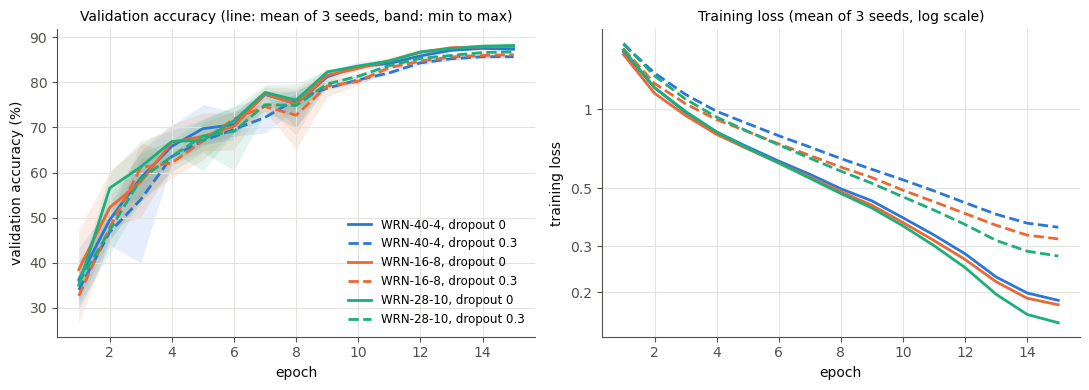

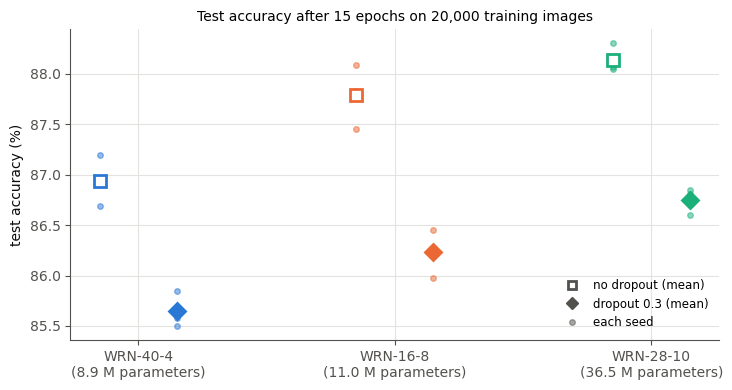

In [8]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
for ci, name in enumerate(order):
    for p, ls in zip(plan["dropouts"], ["-", "--"]):
        runs = [r for r in sweep if f"WRN-{r['job']['depth']}-{r['job']['k']}" == name and r["job"]["dropout"] == p]
        if not runs:
            continue
        va = np.array([r["history"]["val_acc"] for r in runs]) * 100
        tl = np.array([r["history"]["train_loss"] for r in runs])
        ep = np.arange(1, va.shape[1] + 1)
        label = f"{name}, dropout {p:g}"
        a1.plot(ep, va.mean(0), ls, color=SERIES[ci], lw=2, label=label)
        a1.fill_between(ep, va.min(0), va.max(0), color=SERIES[ci], alpha=0.12, lw=0)
        a2.plot(ep, tl.mean(0), ls, color=SERIES[ci], lw=2, label=label)
a1.set_xlabel("epoch"); a1.set_ylabel("validation accuracy (%)")
a1.set_title("Validation accuracy (line: mean of 3 seeds, band: min to max)", fontsize=10)
a2.set_xlabel("epoch"); a2.set_ylabel("training loss"); a2.set_yscale("log")
a2.set_yticks([0.2, 0.3, 0.5, 1], ["0.2", "0.3", "0.5", "1"]); a2.minorticks_off()
a2.set_title("Training loss (mean of 3 seeds, log scale)", fontsize=10)
a1.legend(loc="lower right", fontsize=8.5)
for a in (a1, a2):
    a.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
fig.tight_layout(); fig.savefig(FIG / "p1_p2_curves.png", dpi=200); plt.show()

fig, ax = plt.subplots(figsize=(7.5, 4))
for ci, name in enumerate(order):
    for pi, p in enumerate(plan["dropouts"]):
        sel = df[(df.model == name) & (df.dropout == p)]
        x = ci + (pi - 0.5) * 0.3
        ax.plot([x] * len(sel), sel.test_acc, "o", color=SERIES[ci], ms=4, alpha=0.5)
        ax.plot(x, sel.test_acc.mean(), "D" if p else "s", color=SERIES[ci], ms=8,
                mfc=SERIES[ci] if p else "white", mew=2)
ax.set_xticks(range(len(order)), [f"{n}\n({summary[summary.model == n].params_M.iloc[0]:.1f} M parameters)" for n in order])
ax.set_ylabel("test accuracy (%)")
ax.plot([], [], "s", color=MUTED, mfc="white", mew=2, label="no dropout (mean)")
ax.plot([], [], "D", color=MUTED, label="dropout 0.3 (mean)")
ax.plot([], [], "o", color=MUTED, alpha=0.5, ms=4, label="each seed")
ax.legend(loc="lower right", fontsize=8.5)
ax.set_title("Test accuracy after 15 epochs on 20,000 training images", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "p1_p2_test_accuracy.png", dpi=200); plt.show()

### Σχόλια για τα Ζητούμενα 1 και 2

- **Πλάτος έναντι βάθους.** Το WRN-16-8 (16 επίπεδα, 11,0M παράμετροι) ξεπερνά το βαθύτερο WRN-40-4 (40 επίπεδα, 8,9M παράμετροι) και στο validation (87,94 έναντι 87,35%) και στο test (87,79 έναντι 86,94%), και εκπαιδεύεται λίγο πιο γρήγορα (3,1 έναντι 3,3 λεπτά). Αυτό συμφωνεί με το paper: με λίγο περισσότερες παραμέτρους αλλά 2,5 φορές λιγότερα επίπεδα, το ρηχότερο και πλατύτερο δίκτυο είναι και ακριβέστερο και ταχύτερο, γιατί λίγες πλατιές συνελίξεις αξιοποιούν καλύτερα την παραλληλία της GPU από πολλά διαδοχικά λεπτά επίπεδα.
- **Το μεγαλύτερο δίκτυο κερδίζει με μικρή διαφορά.** Το WRN-28-10 (36,5M παράμετροι) έχει το καλύτερο validation (88,18 ± 0,42%) και επιλέγεται για το Ζητούμενο 3. Η διαφορά του από το WRN-16-8 στο validation (0,24 μονάδες) είναι μικρότερη από την τυπική απόκλιση ανάμεσα στα seeds. Στο test δίνει 88,14 ± 0,14%, δηλαδή 0,35 μονάδες πάνω από το WRN-16-8, ενώ κάθε εκπαίδευση διαρκεί 3,5 φορές περισσότερο (10,7 έναντι 3,1 λεπτά). Με αυτό το σύντομο πρόγραμμα, το WRN-16-8 είναι η πιο αποδοτική επιλογή.
- **Dropout.** Με dropout 0,3 η ακρίβεια στο test πέφτει και στις 9 συγκρίσεις ίδιου μοντέλου και ίδιου seed, κατά 0,8 έως 1,7 μονάδες (1,4 κατά μέσο όρο). Η ακρίβεια εκπαίδευσης της τελευταίας εποχής πέφτει πολύ περισσότερο, κατά 4,6 έως 6,0 μονάδες (για το WRN-28-10 από 95,2 σε 90,7%). Η ακρίβεια εκπαίδευσης μετριέται κατά τη διάρκεια της εποχής, σε επαυξημένες εικόνες και με ενεργό το dropout, οπότε δεν συγκρίνεται άμεσα με το validation. Δείχνει όμως ότι σε 15 εποχές το dropout κυρίως επιβραδύνει τη μάθηση. Στο paper η εκπαίδευση διαρκεί 200 εποχές σε όλες τις 50.000 εικόνες, και ακόμη και εκεί η επίδραση του dropout στο CIFAR-10 είναι μικρή. Με τόσο σύντομη εκπαίδευση η επιπλέον κανονικοποίηση δεν προλαβαίνει να αποδώσει.
- **Καμπύλες.** Το μεγαλύτερο μέρος της τελικής ακρίβειας κερδίζεται στις τελευταίες εποχές, όταν το learning rate μικραίνει με την καμπύλη συνημιτόνου: για το WRN-28-10 χωρίς dropout το validation είναι 83,6% στην εποχή 10 και 88,2% στην εποχή 15. Από την 9η εποχή και μετά, οι καμπύλες με dropout βρίσκονται χαμηλότερα και στα τρία μοντέλα.

## Ζητούμενο 3: MixUp και CIFAR-10-C

Το MixUp (Zhang et al., 2018) εκπαιδεύει το δίκτυο σε γραμμικούς συνδυασμούς ζευγών εικόνων, $\tilde x = \lambda x_i + (1-\lambda) x_j$, με στόχο τον ίδιο συνδυασμό των ετικετών, $\tilde y = \lambda y_i + (1-\lambda) y_j$, όπου $\lambda \sim \mathrm{Beta}(\alpha, \alpha)$. Η απώλεια είναι $\lambda\,\mathrm{CE}(f(\tilde x), y_i) + (1-\lambda)\,\mathrm{CE}(f(\tilde x), y_j)$. Έτσι το δίκτυο μαθαίνει να αλλάζει ομαλά ανάμεσα στις κλάσεις και να μην είναι υπερβολικά σίγουρο.

Για κάθε seed αξιολογούνται τρία μοντέλα: το επιλεγμένο μοντέλο μετά από 15 εποχές, το ίδιο μετά από 5 ακόμη εποχές χωρίς MixUp, και μετά από 5 ακόμη εποχές με MixUp.

In [9]:
mixup_complete = sweep_complete and run_phase("mixup")

[   1.0 min] mixup: 0/9 runs finished
[   2.0 min] mixup: 1/9 runs finished
[   6.0 min] mixup: 2/9 runs finished
[   7.0 min] mixup: 3/9 runs finished
[   8.0 min] mixup: 4/9 runs finished
[  12.0 min] mixup: 5/9 runs finished
[  13.0 min] mixup: 6/9 runs finished
[  14.0 min] mixup: 7/9 runs finished
[  18.0 min] mixup: 8/9 runs finished
[  19.0 min] mixup: 9/9 runs finished
mixup: 9/9 runs finished in 19.0 min


In [10]:
KIND_LABEL = {"base": "15 epochs", "nomixup": "+5 epochs, no MixUp", "mixup": "+5 epochs, MixUp"}
rob = load_results({"base", "nomixup", "mixup"})
groups = plan["corruptions"]
names = rob[0]["cifar10c"]["names"]
rows = []
for r in rob:
    acc = np.array(r["cifar10c"]["acc"]) * 100
    row = dict(model=KIND_LABEL[r["job"]["kind"]], kind=r["job"]["kind"], seed=r["job"]["seed"],
               clean=100 * r["clean"]["acc"], cifar10c=acc.mean())
    for g, members in groups.items():
        row[g] = acc[[names.index(c) for c in members]].mean()
    for s in range(5):
        row[f"severity {s + 1}"] = acc[:, s].mean()
    rows.append(row)
rdf = pd.DataFrame(rows)
rdf.to_csv(TAB / "p3_runs.csv", index=False)
cols = ["clean", "cifar10c", *groups, *[f"severity {s}" for s in range(1, 6)]]
rsum = rdf.groupby("kind")[cols].agg(["mean", "std"]).reindex(list(KIND_LABEL))
rsum.index = [KIND_LABEL[k] for k in rsum.index]
rsum.to_csv(TAB / "p3_summary.csv")
display(rsum[["clean", "cifar10c", *groups]])
display(rsum[[f"severity {s}" for s in range(1, 6)]])

per_c = {k: np.mean([np.array(r["cifar10c"]["acc"]).mean(1) for r in rob if r["job"]["kind"] == k], 0) * 100
         for k in KIND_LABEL}
pd.DataFrame(per_c, index=names).rename(columns=KIND_LABEL).to_csv(TAB / "p3_per_corruption.csv")

clean      cifar10c      noise       blur      weather  \
                     mean  std     mean  std  mean  std  mean  std    mean   
15 epochs           88.15 0.14    67.53 0.94 59.76 1.61 61.81 1.01   76.23   
+5 epochs, no MixUp 88.33 0.26    66.92 0.40 58.77 0.91 60.74 0.46   76.19   
+5 epochs, MixUp    87.99 0.40    68.24 0.31 59.63 0.76 62.22 0.21   77.39   

                         digital       
                     std    mean  std  
15 epochs           0.49   70.39 1.23  
+5 epochs, no MixUp 0.45   69.94 0.87  
+5 epochs, MixUp    0.37   71.59 0.69

severity 1      severity 2      severity 3       \
                          mean  std       mean  std       mean  std   
15 epochs                80.37 0.41      74.76 0.74      69.12 0.97   
+5 epochs, no MixUp      80.24 0.25      74.58 0.33      68.61 0.39   
+5 epochs, MixUp         80.73 0.35      75.58 0.36      70.00 0.25   

                    severity 4      severity 5       
                          mean  std       mean  std  
15 epochs                61.71 1.30      51.70 1.30  
+5 epochs, no MixUp      60.85 0.57      50.33 0.55  
+5 epochs, MixUp         62.62 0.36      52.28 0.32

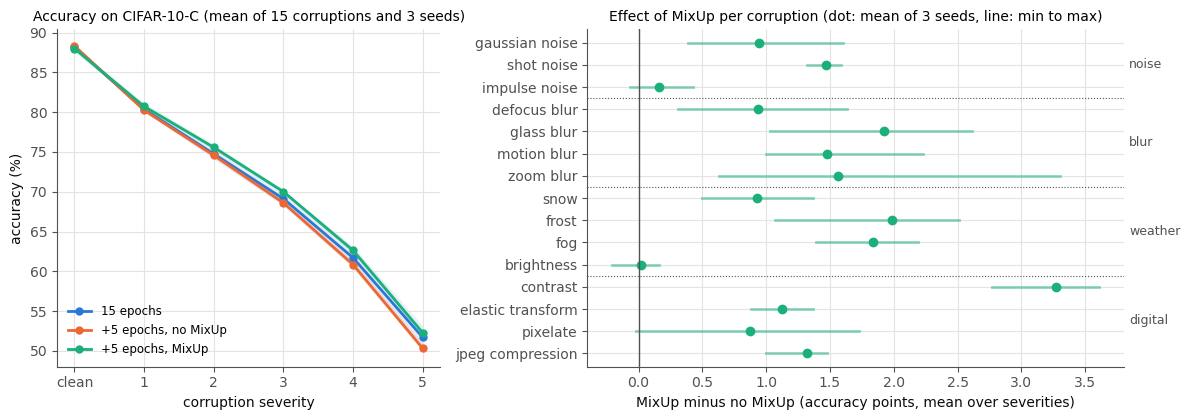

In [11]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [1, 1.4]})
sev_cols = ["clean"] + [f"severity {s}" for s in range(1, 6)]
for ci, k in enumerate(KIND_LABEL):
    sel = rdf[rdf.kind == k][sev_cols].to_numpy()
    a1.plot(range(6), sel.mean(0), "-o", color=SERIES[ci], lw=2, ms=5, label=KIND_LABEL[k])
    a1.fill_between(range(6), sel.min(0), sel.max(0), color=SERIES[ci], alpha=0.12, lw=0)
a1.set_xticks(range(6), ["clean", "1", "2", "3", "4", "5"])
a1.set_xlabel("corruption severity"); a1.set_ylabel("accuracy (%)")
a1.set_title("Accuracy on CIFAR-10-C (mean of 15 corruptions and 3 seeds)", fontsize=10)
a1.legend(loc="lower left", fontsize=8.5)

diff = []
for c in names:
    i = names.index(c)
    d = [100 * (np.mean(rm["cifar10c"]["acc"][i]) - np.mean(rn["cifar10c"]["acc"][i]))
         for rm in rob if rm["job"]["kind"] == "mixup"
         for rn in rob if rn["job"]["kind"] == "nomixup" and rn["job"]["seed"] == rm["job"]["seed"]]
    diff.append(d)
y = np.arange(len(names))[::-1]
for yi, c, d in zip(y, names, diff):   # the MixUp colour of the left panel
    a2.plot([min(d), max(d)], [yi, yi], color=SERIES[2], lw=2, alpha=0.5)
    a2.plot(np.mean(d), yi, "o", color=SERIES[2], ms=6)
a2.axvline(0, color=MUTED, lw=1)
a2.set_yticks(y, [c.replace("_", " ") for c in names])
a2.set_ylim(-0.6, len(names) - 0.4)
for g, members in groups.items():      # corruption groups: name on the right, dotted line between groups
    ys = [y[names.index(c)] for c in members]
    a2.text(1.01, np.mean(ys), g, transform=a2.get_yaxis_transform(), va="center", fontsize=9, color=MUTED)
    if min(ys) > 0:
        a2.axhline(min(ys) - 0.5, color=MUTED, lw=0.8, ls=":")
a2.set_xlabel("MixUp minus no MixUp (accuracy points, mean over severities)")
a2.set_title("Effect of MixUp per corruption (dot: mean of 3 seeds, line: min to max)", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "p3_cifar10c.png", dpi=200, bbox_inches="tight"); plt.show()

### Σχόλια για το Ζητούμενο 3

- **Οι αλλοιώσεις κοστίζουν πολύ.** Το μοντέλο των 15 εποχών πέφτει από 88,15% στο καθαρό test σε 67,53% κατά μέσο όρο στο CIFAR-10-C, και σε 51,70% στη μέγιστη ένταση (5). Ο θόρυβος (59,8%) και το θόλωμα (61,8%) βλάπτουν περισσότερο από τις ψηφιακές (70,4%) και τις καιρικές αλλοιώσεις (76,2%). Η χειρότερη αλλοίωση είναι το glass blur (44,2%). Το μοντέλο αυτό είναι το ίδιο checkpoint με το WRN-28-10 του Ζητουμένου 1, που εκεί έδωσε 88,14%· η νέα αξιολόγηση αλλάζει μία από τις 10.000 προβλέψεις σε δύο seeds, πιθανότατα λόγω μικρών αριθμητικών διαφορών της mixed precision στη GPU.
- **5 εποχές ακόμη χωρίς MixUp.** Η συνέχιση της κανονικής εκπαίδευσης αλλάζει ελάχιστα το καθαρό test (88,33%, +0,18 μονάδες) και μειώνει την ακρίβεια στο CIFAR-10-C σε 66,92% (−0,61 μονάδες, από −0,04 έως −1,19 ανά seed). Πιθανότατα το δίκτυο προσαρμόζεται περισσότερο στις καθαρές εικόνες εκπαίδευσης (η ακρίβεια εκπαίδευσης φτάνει 96,6–97,1%) και γίνεται λίγο λιγότερο ανθεκτικό στις αλλοιώσεις.
- **MixUp.** Σε σύγκριση με τις ίδιες 5 εποχές χωρίς MixUp, το MixUp ανεβάζει την ακρίβεια στο CIFAR-10-C σε 68,24% (+1,32 μονάδες), και η βελτίωση εμφανίζεται σε κάθε seed (+1,21, +1,43, +1,33). Στο καθαρό test χάνει 0,34 μονάδες (87,99%· −0,21, −0,50, −0,32 ανά seed). Η ακρίβεια εκπαίδευσης με MixUp (85,3–86,5%) μετριέται στις αναμεμειγμένες εικόνες και δεν συγκρίνεται με το 96,6–97,1% χωρίς MixUp.
- **Το κέρδος μεγαλώνει με την ένταση της αλλοίωσης:** +0,49 μονάδες στην ένταση 1 και +1,95 στην ένταση 5. Ανά ομάδα, το κέρδος είναι +1,65 στις ψηφιακές αλλοιώσεις, +1,48 στο θόλωμα, +1,19 στις καιρικές και +0,86 στον θόρυβο.
- **Ανά αλλοίωση.** Το μεγαλύτερο κέρδος είναι στο contrast (+3,27, από 65,97 σε 69,24%), ακολουθούν το frost (+1,99), το glass blur (+1,93) και το fog (+1,84). Μια πιθανή εξήγηση: η ανάμειξη δύο εικόνων μειώνει την αντίθεση της καθεμιάς και προσθέτει από πάνω μια ξένη υφή, που μοιάζει με αυτές τις αλλοιώσεις. Σχεδόν κανένα κέρδος δεν υπάρχει στο brightness (+0,02), που ούτως ή άλλως βλάπτει ελάχιστα (85,9% έναντι 88,3% στο καθαρό test), και στο impulse noise (+0,16).

## Bonus: βεβαιότητα των προβλέψεων

Βεβαιότητα μιας πρόβλεψης είναι η μεγαλύτερη πιθανότητα του softmax. Συγκρίνουμε τη μέση βεβαιότητα στις σωστές και στις λάθος προβλέψεις και την κατανομή της, στο καθαρό test set και στο CIFAR-10-C. Μετράμε επίσης το *expected calibration error* (ECE): οι προβλέψεις χωρίζονται σε 15 διαστήματα βεβαιότητας και υπολογίζεται η μέση απόσταση ανάμεσα στη βεβαιότητα και στην πραγματική ακρίβεια κάθε διαστήματος, σταθμισμένη με το πλήθος των προβλέψεων. Ένα καλά βαθμονομημένο μοντέλο που δηλώνει 80% βεβαιότητα έχει δίκιο περίπου στο 80% των περιπτώσεων.

In [12]:
crow = []
for r in rob:
    for split, st in (("clean test", r["clean"]), ("CIFAR-10-C", r["cifar10c"]["confidence"])):
        crow.append(dict(model=KIND_LABEL[r["job"]["kind"]], kind=r["job"]["kind"], seed=r["job"]["seed"], data=split,
                         accuracy=100 * st["acc"], conf_right=100 * st["mean_conf_right"],
                         conf_wrong=100 * st["mean_conf_wrong"], ece=100 * st["ece"]))
cdf = pd.DataFrame(crow)
cdf.to_csv(TAB / "bonus_confidence_runs.csv", index=False)
csum = cdf.groupby(["data", "kind"])[["accuracy", "conf_right", "conf_wrong", "ece"]].agg(["mean", "std"])
csum = csum.reindex([(d, k) for d in ("clean test", "CIFAR-10-C") for k in KIND_LABEL])
csum.index = [f"{d}: {KIND_LABEL[k]}" for d, k in csum.index]
csum.to_csv(TAB / "bonus_confidence_summary.csv")
display(csum)

accuracy      conf_right      conf_wrong       \
                                    mean  std       mean  std       mean  std   
clean test: 15 epochs              88.15 0.14      94.29 0.16      70.11 0.39   
clean test: +5 epochs, no MixUp    88.33 0.26      95.12 0.21      72.10 0.47   
clean test: +5 epochs, MixUp       87.99 0.40      86.71 0.53      55.34 0.80   
CIFAR-10-C: 15 epochs              67.53 0.94      88.74 0.25      66.99 0.95   
CIFAR-10-C: +5 epochs, no MixUp    66.92 0.40      90.12 0.09      70.01 0.26   
CIFAR-10-C: +5 epochs, MixUp       68.24 0.31      78.68 0.54      54.79 0.40   

                                  ece       
                                 mean  std  
clean test: 15 epochs            3.39 0.12  
clean test: +5 epochs, no MixUp  4.14 0.11  
clean test: +5 epochs, MixUp     5.05 0.31  
CIFAR-10-C: 15 epochs           14.15 1.19  
CIFAR-10-C: +5 epochs, no MixUp 16.55 0.44  
CIFAR-10-C: +5 epochs, MixUp     2.85 0.64

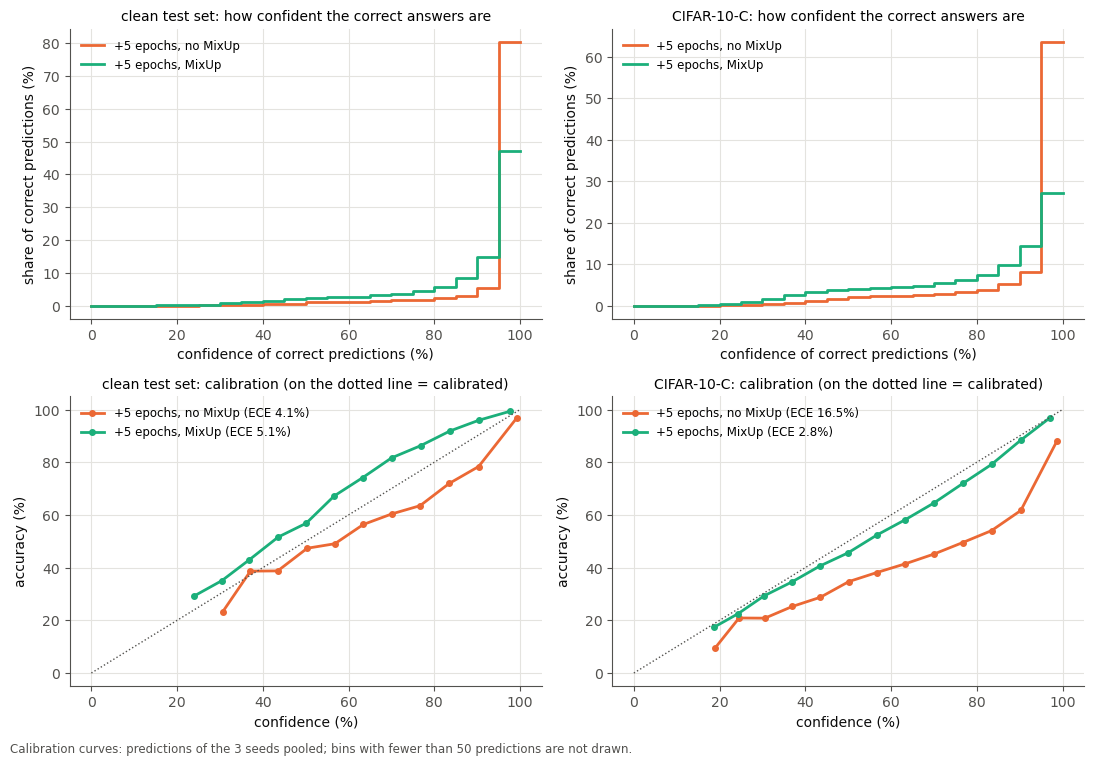

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
edges = np.linspace(0, 1, 21)
for col, (split, get) in enumerate((("clean test set", lambda r: r["clean"]),
                                    ("CIFAR-10-C", lambda r: r["cifar10c"]["confidence"]))):
    ah, ar = axes[0, col], axes[1, col]
    for ci, k in enumerate(["nomixup", "mixup"]):
        st = [get(r) for r in rob if r["job"]["kind"] == k]
        h = np.sum([s["hist_right"] for s in st], 0).astype(float)
        ah.step(100 * edges, 100 * np.append(h, h[-1]) / h.sum(), where="post", color=SERIES[ci + 1], lw=2,
                label=KIND_LABEL[k])
        cnt = np.sum([s["bin_count"] for s in st], 0)
        acc = np.array([np.nansum([s["bin_acc"][b] * s["bin_count"][b] for s in st if s["bin_count"][b]]) for b in range(15)])
        conf = np.array([np.nansum([s["bin_conf"][b] * s["bin_count"][b] for s in st if s["bin_count"][b]]) for b in range(15)])
        ok = cnt >= 50   # bins with fewer predictions are too noisy to draw (the ECE uses every bin)
        ar.plot(100 * conf[ok] / cnt[ok], 100 * acc[ok] / cnt[ok], "-o", color=SERIES[ci + 1], lw=2, ms=4,
                label=f"{KIND_LABEL[k]} (ECE {100 * np.mean([s['ece'] for s in st]):.1f}%)")
    ah.set_xlabel("confidence of correct predictions (%)"); ah.set_ylabel("share of correct predictions (%)")
    ah.set_title(f"{split}: how confident the correct answers are", fontsize=10)
    ah.legend(loc="upper left", fontsize=8.5)
    ar.plot([0, 100], [0, 100], color=MUTED, lw=1, ls=":")
    ar.set_xlabel("confidence (%)"); ar.set_ylabel("accuracy (%)")
    ar.set_title(f"{split}: calibration (on the dotted line = calibrated)", fontsize=10)
    ar.legend(loc="upper left", fontsize=8.5)
fig.tight_layout()
fig.text(0.01, -0.01, "Calibration curves: predictions of the 3 seeds pooled; bins with fewer than 50 predictions "
         "are not drawn.", fontsize=8.5, color=MUTED)
fig.savefig(FIG / "bonus_confidence.png", dpi=200, bbox_inches="tight"); plt.show()

### Σχόλια για το Bonus

- **Το MixUp μειώνει τη βεβαιότητα.** Οι στόχοι του MixUp είναι μείγματα ετικετών, οπότε το δίκτυο δεν μαθαίνει να δίνει πιθανότητα σχεδόν 1 σε μία κλάση. Στο καθαρό test, χωρίς MixUp το 80% των σωστών προβλέψεων έχει βεβαιότητα τουλάχιστον 95%· με MixUp μόνο το 47%. Η μέση βεβαιότητα των σωστών προβλέψεων πέφτει από 95,1 σε 86,7% και των λάθος από 72,1 σε 55,3%.
- **Λιγότερα σίγουρα λάθη.** Χωρίς MixUp το 16,7% των λάθος προβλέψεων στο καθαρό test έχει βεβαιότητα τουλάχιστον 95%· με MixUp μόνο το 1,7%. Η διαφορά βεβαιότητας ανάμεσα σε σωστές και λάθος προβλέψεις μεγαλώνει από 23 σε 31 μονάδες στο καθαρό test και από 20 σε 24 μονάδες στο CIFAR-10-C. Άρα με MixUp η βεβαιότητα ξεχωρίζει καλύτερα ποιες προβλέψεις αξίζουν εμπιστοσύνη.
- **Καθαρό test: από υπερβολική σιγουριά σε υπερβολικό δισταγμό.** Χωρίς MixUp το μοντέλο είναι υπερβολικά σίγουρο: μέση βεβαιότητα 92,4% για ακρίβεια 88,3%, ECE 4,14%. Με MixUp γίνεται υπερβολικά διστακτικό: μέση βεβαιότητα 82,9% για ακρίβεια 88,0%. Η καμπύλη βαθμονόμησης περνά πάνω από τη διαγώνιο και το ECE ανεβαίνει σε 5,05%. Στο καθαρό test, λοιπόν, το MixUp δεν βελτιώνει τη βαθμονόμηση.
- **CIFAR-10-C: πολύ καλύτερη βαθμονόμηση.** Χωρίς MixUp η ακρίβεια πέφτει πολύ περισσότερο από τη βεβαιότητα: μέση βεβαιότητα 83,5% για ακρίβεια 66,9%, ECE 16,55%. Με MixUp η μέση βεβαιότητα (71,1%) είναι κοντά στην ακρίβεια (68,2%) και το ECE πέφτει σε 2,85%. Η μείωση εμφανίζεται σε κάθε seed (13,3 έως 14,1 μονάδες). Εκεί που το μοντέλο κάνει τα περισσότερα λάθη, το MixUp κάνει τη βεβαιότητά του πολύ πιο αξιόπιστη.
- Οι 5 επιπλέον εποχές χωρίς MixUp κάνουν το μοντέλο πιο σίγουρο από το μοντέλο των 15 εποχών: το ECE ανεβαίνει από 3,39 σε 4,14% στο καθαρό test και από 14,15 σε 16,55% στο CIFAR-10-C.

## Συμπεράσματα

1. **Πλάτος αντί για βάθος.** Με λίγο περισσότερες παραμέτρους (11,0M έναντι 8,9M) αλλά 2,5 φορές λιγότερα επίπεδα, το ρηχό και πλατύ WRN-16-8 είναι ακριβέστερο και ταχύτερο από το βαθύ WRN-40-4. Το πολύ μεγαλύτερο WRN-28-10 είναι το καλύτερο, αλλά μόνο κατά 0,35 μονάδες στο test, με 3,5 φορές μεγαλύτερο χρόνο εκπαίδευσης.
2. **Το dropout δεν βοηθά σε σύντομη εκπαίδευση.** Με 15 εποχές και 20.000 εικόνες, το dropout 0,3 μειώνει την ακρίβεια στο test κατά 1,4 μονάδες κατά μέσο όρο, σε κάθε μοντέλο και seed.
3. **Το MixUp ανταλλάσσει λίγη καθαρή ακρίβεια με ανθεκτικότητα.** Χάνει 0,34 μονάδες στο καθαρό test και κερδίζει 1,32 στο CIFAR-10-C. Το κέρδος μεγαλώνει με την ένταση της αλλοίωσης και είναι μεγαλύτερο σε αλλοιώσεις που μοιάζουν με ανάμειξη εικόνων, όπως το contrast και το fog.
4. **Το MixUp κάνει τη βεβαιότητα πιο αξιόπιστη εκεί που χρειάζεται.** Στο CIFAR-10-C το ECE πέφτει από 16,55 σε 2,85%, και τα λάθη με βεβαιότητα πάνω από 95% σχεδόν εξαφανίζονται. Στο καθαρό test όμως το μοντέλο γίνεται υπερβολικά διστακτικό (ECE 5,05%).
5. **Όρια.** Με 15 εποχές και 20.000 εικόνες εκπαίδευσης η ακρίβεια (περίπου 88%) είναι αρκετά κάτω από το περίπου 96% του paper για το WRN-28-10. Τα συμπεράσματα για το dropout ίσως αλλάζουν με πλήρη εκπαίδευση. Το CIFAR-10-C αξιολογείται σε 2.000 από τις 10.000 εικόνες για κάθε αλλοίωση και ένταση, δηλαδή σε 150.000 εικόνες συνολικά.

## Αποθήκευση

In [14]:
summary_json = dict(
    plan=plan, best=best,
    sweep=summary.assign(model=summary.model.astype(str)).to_dict(orient="records"),
    robustness={KIND_LABEL[k]: {c: float(rdf[rdf.kind == k][c].mean()) for c in cols} for k in KIND_LABEL} if rob else {},
    device=sweep[0]["device"] if sweep else None, complete=bool(mixup_complete),
    hours=(time.time() - START) / 3600)
(OUT / "summary.json").write_text(json.dumps(summary_json, indent=1))
archive = shutil.make_archive(str(WORK / ("lab1_outputs_smoke" if SMOKE else "lab1_outputs")), "zip", OUT)
print("Saved", archive, f"({Path(archive).stat().st_size / 1e6:.1f} MB);",
      f"total time {(time.time() - START) / 3600:.2f} h; complete: {mixup_complete}")

Saved /kaggle/working/lab1_outputs.zip (0.8 MB); total time 1.93 h; complete: True
